In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
a = 	[ 1.39,	1.28,	1.27,	1.26,	1.25,	1.24,	1.22,	1.21,	1.19,	1.18 ]
b = 	[ 1.27,	1.53,	1.55,	1.58,	1.62,	1.66,	1.71,	1.76,	1.82,	1.89 ]
c = 	[ 0.39,	0.30,	0.31,	0.32,	0.33,	0.34,	0.34,	0.35,	0.35,	0.36 ]
s = 	[ 0.50,	0.60,	0.70,	0.80,	0.90,	1.00,	0.80,	0.70,	0.60,	0.50 ]

In [4]:
a = tf.constant(a)
b = tf.constant(b)
c = tf.constant(c)
s = tf.constant(s)

x = np.linspace(0, 1, 11)

In [5]:
nn = 10
Y = np.zeros((len(x), len(a)))
for ii in range(len(a)):
    Y[:,ii] = a[ii] * np.exp(-b[ii]*x[:]) - c[ii]
Y = np.round(Y, 2)
Y.shape

(11, 10)

In [6]:
# Y = tf.constant(Y)
saida = np.transpose( np.array( [ Y[:,0], Y[:,5] ] ) )
saida.shape, saida

((11, 2), array([[ 1.  ,  0.9 ],
        [ 0.83,  0.71],
        [ 0.69,  0.55],
        [ 0.56,  0.41],
        [ 0.45,  0.3 ],
        [ 0.35,  0.2 ],
        [ 0.26,  0.12],
        [ 0.18,  0.05],
        [ 0.11, -0.01],
        [ 0.05, -0.06],
        [ 0.  , -0.1 ]]))

In [7]:
XX = np.ones((len(x), 3))
XX[:,0] = x
XX[:,1] = s[0] * XX[:,1]
XX[:,2] = s[5] * XX[:,2]
XX

array([[0. , 0.5, 1. ],
       [0.1, 0.5, 1. ],
       [0.2, 0.5, 1. ],
       [0.3, 0.5, 1. ],
       [0.4, 0.5, 1. ],
       [0.5, 0.5, 1. ],
       [0.6, 0.5, 1. ],
       [0.7, 0.5, 1. ],
       [0.8, 0.5, 1. ],
       [0.9, 0.5, 1. ],
       [1. , 0.5, 1. ]])

In [8]:
XX.shape

(11, 3)

In [9]:
# Set random seed
tf.random.set_seed(42)

# Create a model using the Sequential API
model = tf.keras.Sequential([
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(2, activation='linear')
])

In [10]:
# Compile the model
model.compile(loss=tf.keras.losses.mae, # mae is short for mean absolute error
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # SGD is short for stochastic gradient descent
              metrics=["mse","mae"])

In [11]:
# Fit the model
# model.fit(X, y, epochs=5) # this will break with TensorFlow 2.7.0+
# history = model.fit(tf.expand_dims(X, axis=-1), saida, epochs=500, verbose=0)
history = model.fit(XX, saida, epochs=1000, verbose=0)
print("treinada...")

treinada...


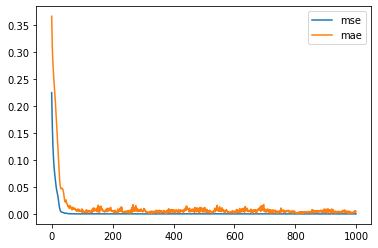

In [12]:
plt.plot(history.history["mse"], label="mse")
plt.plot(history.history["mae"], label="mae")
plt.legend()
plt.show()

32/32 [==============================] - 0s 1ms/step


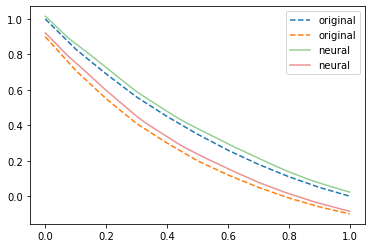

In [13]:
xx_pred = np.ones((1000,3))
xx_pred[:,0] = np.linspace(0, 1, 1000)
xx_pred[:,1] = s[1] * xx_pred[:,1]
xx_pred[:,1] = s[5] * xx_pred[:,1]
y_pred = model.predict(xx_pred)
plt.plot(x, saida, label='original', ls='--')
plt.plot(xx_pred[:,0], y_pred, label='neural', alpha=0.5)
plt.legend()
plt.show()